In [1]:
# Force remove any broken fragments
# !pip uninstall torch torchvision torchaudio -y
# Run this once if pytorch-grad-cam is not installed.
# Uncomment the next line if necessary.

!pip install grad-cam -q
# !pip install torch torchvision

import os
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Circle

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


warnings.filterwarnings("ignore")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 83.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Mounted at /content/drive
Device: cuda

CSV columns:
['patient_id', 'image', 'BG', 'class', 'severity', 'X', 'Y', 'RADIUS', 'label']

Loading model...
Model loaded successfully.
Model type: FinalMIL

Original image:
H = 1024
W = 1024

MIAS annotation:
X=546.0, Y=463.0, R=33.0

NumPy coordinate:
X=546.0, Y=560.0, R=33.0

Bag shape: torch.Size([60, 3, 224, 224])

MIL PREDICTION
Logit: -0.2581482529640198
Malignant probability: 0.43581894040107727
True label: 1
Class: MISC
Severity: B

Grad-CAM target layer: Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, af

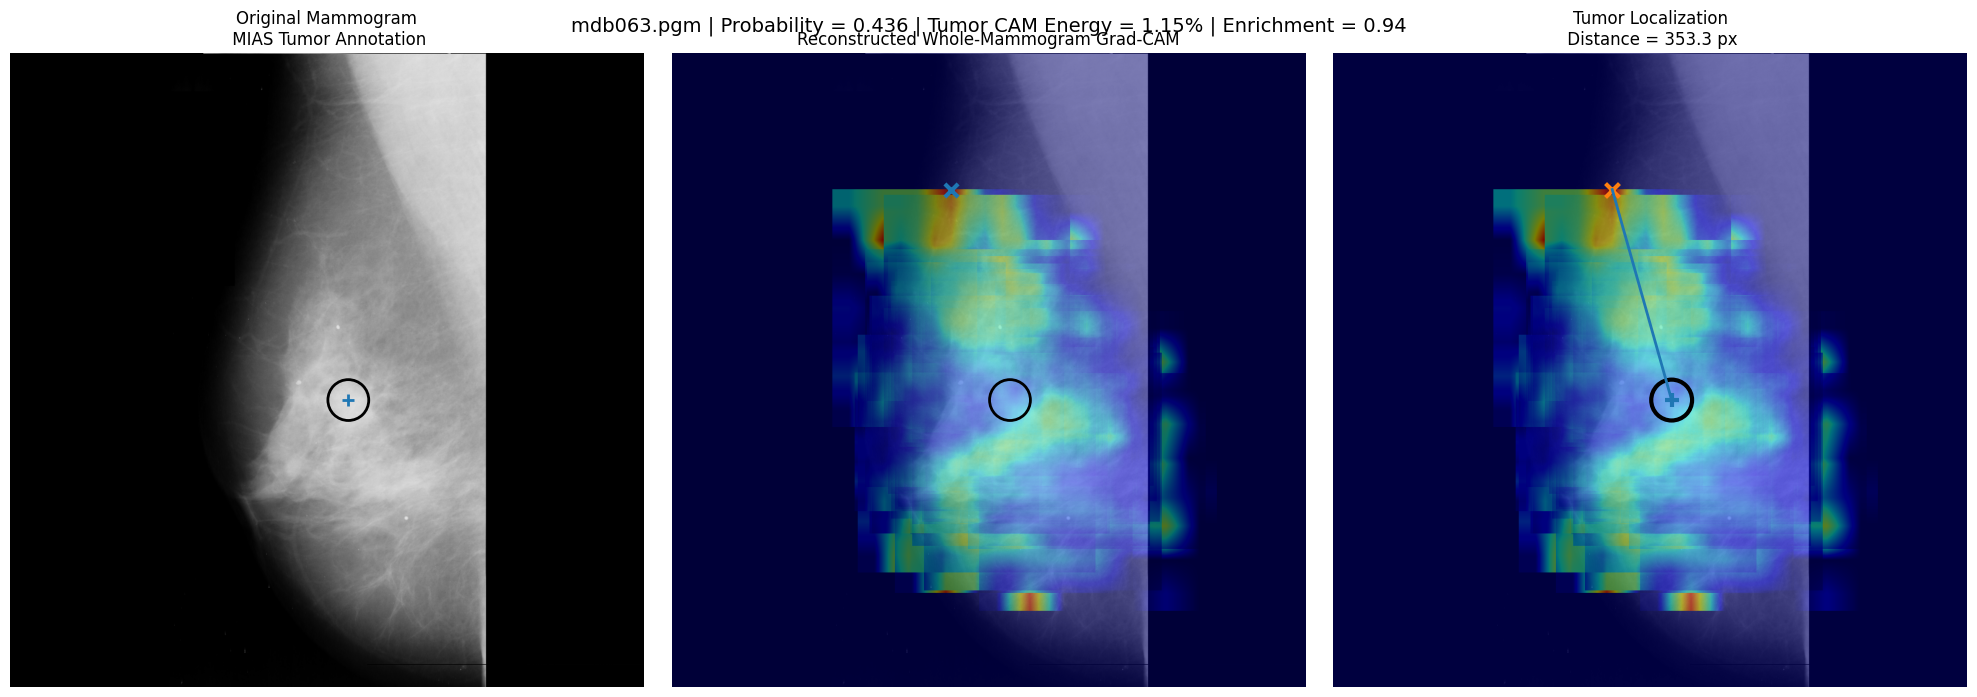


Figure saved to: /content/drive/My Drive/GradCAM_mdb063.png

FINAL SUMMARY:


,image,Bag_probability,MIAS_X,MIAS_Y,Tumor_X_numpy,Tumor_Y_numpy,Tumor_radius_px,CAM_peak_X,CAM_peak_Y,Tumor_CAM_energy_percent,Double_CAM_energy_percent,Tumor_area_percent,Double_Tumor_area_percent,CAM_enrichment,Double_CAM_enrichment,Peak_distance_px,Peak_inside_tumor,CAM_centroid_X,CAM_centroid_Y,Centroid_distance_px
0,mdb063.pgm,0.435819,546.0,463.0,546.0,560.0,33.0,450,220,1.152078,5.298903,1.220639,1.220639,0.943832,4.34109,353.293079,False,525.54822,541.136866,27.822529


In [2]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

from google.colab import drive
drive.mount('/content/drive')

CSV_PATH = '/content/drive/My Drive/mias_info.csv'
IMG_DIR = '/content/drive/My Drive/MIAS/copy_images'
MODEL_PATH = '/content/drive/My Drive/my_5th_best_model_ResNet50_3.pth'


# ------------------------------------------------------------
# Select image
# ------------------------------------------------------------

# Example from your CSV:
# mdb023.pgm  CIRC  M  X=538  Y=681  R=29

CASE_IMAGE = "mdb063.pgm"

# ------------------------------------------------------------
# Model / dataset parameters
# ------------------------------------------------------------

BAG_SIZE = 60
PATCH_SIZE = 224
SCALES = [128, 224, 384]
MULTISCALE = True

# ------------------------------------------------------------
# Grad-CAM settings
# ------------------------------------------------------------
# Last convolutional feature block of EfficientNet-B0#
# EfficientNet-B0:#
# model.backbone.features#
# The last feature layer retains spatial information.
#
#GRADCAM_LAYER_INDEX = -1   # for EfficientB0
GRADCAM_LAYER_INDEX = 7    # for ResNet50 & ResNet18
#GRADCAM_LAYER_INDEX = features.denseblock4.denselayer16.conv2

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 4532

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# ============================================================
# 2. LOAD CSV
# ============================================================

df = pd.read_csv(CSV_PATH)

print("\nCSV columns:")
print(df.columns.tolist())

# ============================================================
# 3. LOAD MODEL CLASSES
# ============================================================

# ------------------------------------------------------------
# EfficientNet-B0 backbone
# ------------------------------------------------------------
#### RESNET18 ##########################
class ResNet18Backbone(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        base = models.resnet18(weights='DEFAULT')
        self.features = nn.Sequential(*list(base.children())[:-1])  # remove FC
        self.out_dim = 512

    def forward(self, x):
        x = self.features(x)           # [N, 512, 1, 1]
        x = x.view(x.size(0), -1)      # [N, 512]
        return x

###### RESNET50 ##########################
class ResNet50Backbone(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()
        if pretrained:
            base = models.resnet50(weights='DEFAULT')
        else:
            base = models.resnet50(weights=None)

        # Remove final FC layer
        self.features = nn.Sequential(
            *list(base.children())[:-1]
        )

        # ResNet50 output dimension
        self.out_dim = 2048

    def forward(self, x):

        # [N, 2048, 1, 1]
        x = self.features(x)
        # [N, 2048]
        x = x.view(x.size(0), -1)
        return x

####### DenseNet121 ########################
class DenseNet121Backbone(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()
        if pretrained:
            base = models.densenet121(weights='DEFAULT')
        else:
            base = models.densenet121(weights=None)
        # Feature extractor only
        self.features = base.features
        # Output feature dimension
        self.out_dim = 1024

    def forward(self, x):

        # [N, 1024, H, W]
        x = self.features(x)
        # ReLU (important for DenseNet)
        x = F.relu(x, inplace=True)
        # Global average pooling
        x = F.adaptive_avg_pool2d(x, (1,1))
        # [N, 1024]
        x = torch.flatten(x, 1)
        return x

class EfficientNetB0Backbone(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()

        if pretrained:
            base = models.efficientnet_b0(weights="DEFAULT")
        else:
            base = models.efficientnet_b0(wights=None)

        self.features = base.features
        self.out_dim = 1280

    def forward(self, x):

        x = self.features(x)
        x = F.adaptive_avg_pool2d(x, (1, 1))
        x = torch.flatten(x, 1)
        return x

# ------------------------------------------------------------
# Stable Gated Attention
# ------------------------------------------------------------
class StableGatedAttention(nn.Module):

    def __init__(
        self,
        #in_dim=512,		    # for renet18
      	in_dim=2048,		    # for resnet50
      	#in_dim=1024,		    # for DenseNet121
      	#in_dim=1280,		    # for EfficientNet-B0
        #hidden_dim=128,    # reduced for small data for resnet18
        hidden_dim=256,     # for resnet50, DenseNet and EfficientsNet
        dropout=0.1,
        temperature=0.7     # smoother attention
        ):

        super().__init__()

        self.temperature = temperature
        self.V = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.Tanh())
        self.U = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.Sigmoid())
        self.dropout = nn.Dropout(dropout)
        self.w = nn.Linear(hidden_dim, 1)
        self.norm = nn.LayerNorm(in_dim)

    def forward(self, H):

        H = self.norm(H)
        V = self.V(H)
        U = self.U(H)
        G = V * U
        G_dropped = self.dropout(G)
        A_logits = (2.0 * self.w(G_dropped))

        A = torch.softmax(A_logits / self.temperature, dim=0)
        M = torch.sum(A * H, dim=0)

        return M, A

# ------------------------------------------------------------
# Final MIL model
# ------------------------------------------------------------
class FinalMIL(nn.Module):

    def __init__(self, dropout=0.1):

        super().__init__()

        #self.backbone = ResNet18Backbone()
        self.backbone = ResNet50Backbone()
        #self.backbone = DenseNet121Backbone()
        #self.backbone = EfficientNetB0Backbone()
        self.attention = StableGatedAttention(self.backbone.out_dim)

        # Same as your training code
        for param in self.backbone.parameters():
            param.requires_grad = False

        self.projector = nn.Sequential(
            #nn.Linear(512, 256),		# for resnet18
          	nn.Linear(2048, 256),		# for resnet50
          	#nn.Linear(1024, 256),		# for DenseNet121
          	#nn.Linear(1280, 256),		# for EfficientNet-B0
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.bag_classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

        self.instance_classifier = nn.Sequential(

            nn.Linear(1280, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, bag):

        # ----------------------------------------------------
        # Feature extraction
        # ----------------------------------------------------

        feats = self.backbone(bag)

        # ----------------------------------------------------
        # Attention
        # ----------------------------------------------------

        M, A = self.attention(feats)
        M = self.projector(M)

        # ----------------------------------------------------
        # Top-K
        # ----------------------------------------------------

        k = max(5, int(0.2 * len(A.squeeze())))
        topk_idx = torch.topk(A.squeeze(), k).indices

        topk_feats = feats[topk_idx]

        topk_feat = topk_feats.mean(dim=0)
        topk_feat = self.projector(topk_feat)

        # ----------------------------------------------------
        # Concatenate
        # ----------------------------------------------------

        M = torch.cat([M, topk_feat], dim=0)

        # ----------------------------------------------------
        # Bag prediction
        # ----------------------------------------------------

        out = self.bag_classifier(M)

        return out, A, feats

# ============================================================
# 4. LOAD TRAINED MODEL
# ============================================================

print("\nLoading model...")

model = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")
print("Model type:", type(model).__name__)

# ============================================================
# 5. LOAD IMAGE
# ============================================================

row = df[df["image"].astype(str) == CASE_IMAGE]

if len(row) == 0:
    raise ValueError(f"{CASE_IMAGE} was not found in CSV.")

row = row.iloc[0]

# ------------------------------------------------------------
# Read annotation
# ------------------------------------------------------------

mi_x = row["X"]
mi_y = row["Y"]
mi_radius = row["RADIUS"]
label = row["label"]
case_class = row["class"]
severity = row["severity"]

if pd.isna(mi_x) or pd.isna(mi_y):
    raise ValueError("Selected image has no tumor coordinates.")

mi_x = float(mi_x)
mi_y = float(mi_y)
mi_radius = float(mi_radius)

# ============================================================
# 6. LOAD ORIGINAL MAMMOGRAM
# ============================================================

image_path = os.path.join(IMG_DIR, CASE_IMAGE)

if not os.path.exists(image_path):
    raise FileNotFoundError(image_path)

pil_img = Image.open(image_path).convert("RGB")
img_np = np.asarray(pil_img)
H, W, C = img_np.shape

print("\nOriginal image:")
print("H =", H)
print("W =", W)

# ============================================================
# 7. MIAS → NUMPY COORDINATE CONVERSION
# ============================================================

# MIAS:
#
#       (0,0)
#        │
#        │
#        ↓
#      bottom-left
#
# NumPy:
#
#      (0,0) ─────────→ X
#        │
#        │
#        ↓
#        Y
#
# Therefore:
#
# x_numpy = X_mias
# y_numpy = H - 1 - Y_mias


tumor_x = mi_x
tumor_y = (H - 1) - mi_y

print("\nMIAS annotation:")
print(f"X={mi_x:.1f}, Y={mi_y:.1f}, R={mi_radius:.1f}")
print("\nNumPy coordinate:")
print(f"X={tumor_x:.1f}, Y={tumor_y:.1f}, R={mi_radius:.1f}")

# ============================================================
# 8. CREATE TENSOR IMAGE
# ============================================================

img_tensor = (torch.from_numpy(img_np).permute(2, 0, 1).float() / 255.0)

# ============================================================
# 9. BREAST MASK
# ============================================================

def get_breast_mask(img_np):

    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    gray = cv2.blur(gray, (5, 5))
    thresh = np.percentile(gray, 20)

    return gray > thresh

# Need OpenCV here
import cv2

breast_mask = get_breast_mask(img_np)

# ============================================================
# 10. REPRODUCE YOUR PATCH SAMPLING
# ============================================================

# This follows your existing sampling strategy:
#
# abnormal image:
#
#   exact lesion center
#   lesion-near patches
#   contextual patches
#
# Your training code uses:
#
#   scales = [128, 224, 384]
#
# and 60 patches total.
#
# Because each scale receives 20 patches:
#
#   patches 0-19  -> 128
#   patches 20-39 -> 224
#   patches 40-59 -> 384


num_scales = len(SCALES)
base = BAG_SIZE // num_scales
remainder = BAG_SIZE % num_scales

patches_per_scale = {}

for i, scale in enumerate(SCALES):

    if i < remainder:
        patches_per_scale[scale] = (base + 1)
    else:
        patches_per_scale[scale] = base

# ------------------------------------------------------------
# Build patches
# ------------------------------------------------------------

final_patches = []
final_metadata = []

for scale in SCALES:

    desired_count = patches_per_scale[scale]
    half = scale // 2

    # --------------------------------------------------------
    # Lesion-centered sampling
    # --------------------------------------------------------

    centers = []

    # Exact tumor center
    centers.append([tumor_x, tumor_y])

    # Near lesion
    for _ in range(desired_count // 2):

        dx = np.random.randint(-60, 60)
        dy = np.random.randint(-60, 60)

        nx = np.clip(tumor_x + dx, half, W - half)
        ny = np.clip(tumor_y + dy, half, H - half)

        centers.append([nx, ny])

    # Contextual patches
    while len(centers) < desired_count:

        dx = np.random.randint(-150, 150)
        dy = np.random.randint(-150, 150)

        nx = np.clip(tumor_x + dx, half, W - half)
        ny = np.clip(tumor_y + dy, half, H - half)

        centers.append([nx, ny])

    # --------------------------------------------------------
    # Extract patches
    # --------------------------------------------------------

    scale_patches = []
    scale_metadata = []

    for center_x, center_y in centers:

        center_x = int(np.clip(center_x, half, W - half))
        center_y = int(np.clip(center_y, half, H - half))

        x1 = int(center_x - half)
        y1 = int(center_y - half)

        raw_patch = img_tensor[:, y1:y1 + scale, x1:x1 + scale]

        if (raw_patch.shape[1] != scale or raw_patch.shape[2] != scale):
            continue

        # ----------------------------------------------------
        # Tissue validation
        # ----------------------------------------------------

        mask_patch = breast_mask[y1:y1 + scale, x1:x1 + scale]
        tissue_ratio = mask_patch.mean()

        if scale <= 128:
            tissue_threshold = 0.35
        elif scale <= 224:
            tissue_threshold = 0.25
        else:
            tissue_threshold = 0.15

        if tissue_ratio < tissue_threshold:
            continue

        # ----------------------------------------------------
        # Resize to CNN input
        # ----------------------------------------------------

        patch = F.interpolate(
            raw_patch.unsqueeze(0),
            size=(PATCH_SIZE, PATCH_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        scale_patches.append(patch)
        scale_metadata.append({"x1": x1, "y1": y1, "scale": scale, "cx": center_x, "cy": center_y})

    # --------------------------------------------------------
    # Fallback
    # --------------------------------------------------------

    if len(scale_patches) == 0:
        center_x = np.random.randint(half, W - half)
        center_y = np.random.randint(half, H - half)

        x1 = center_x - half
        y1 = center_y - half

        raw_patch = img_tensor[:, y1:y1 + scale, x1:x1 + scale]

        patch = F.interpolate(raw_patch.unsqueeze(0), size=(PATCH_SIZE, PATCH_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        scale_patches.append(patch)
        scale_metadata.append({"x1": x1, "y1": y1, "scale": scale, "cx": center_x, "cy": center_y})

    # --------------------------------------------------------
    # Padding
    # --------------------------------------------------------

    while len(scale_patches) < desired_count:

        rand_idx = np.random.randint(len(scale_patches))
        scale_patches.append(scale_patches[rand_idx].clone())
        scale_metadata.append(scale_metadata[rand_idx].copy())

    # --------------------------------------------------------
    # Trim
    # --------------------------------------------------------

    scale_patches = (scale_patches[:desired_count])
    scale_metadata = (scale_metadata[:desired_count])

    # --------------------------------------------------------
    # Collect
    # --------------------------------------------------------

    final_patches.extend(scale_patches)
    final_metadata.extend(scale_metadata)

# ============================================================
# 11. STACK BAG
# ============================================================

bag = torch.stack(final_patches)

# Safety check
if bag.shape[0] != BAG_SIZE:
    raise RuntimeError(f"Expected {BAG_SIZE} patches, got {bag.shape[0]}")

# ============================================================
# 12. NORMALIZATION
# ============================================================

normalize_transform = T.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)
bag = normalize_transform(bag)
bag = bag.to(DEVICE)

print("\nBag shape:", bag.shape)

# ============================================================
# 13. BAG PREDICTION
# ============================================================

#with torch.no_grad():
model.eval()
bag_logits, attention, feats = model(bag)

probability = torch.sigmoid(bag_logits.squeeze()).item()
attention_np = (attention.squeeze().detach().cpu().numpy())

print("\n==============================")
print("MIL PREDICTION")
print("==============================")

print("Logit:", float(bag_logits.squeeze().detach().cpu()))
print("Malignant probability:", probability)
print("True label:", int(label))
print("Class:", case_class)
print("Severity:", severity)

# ============================================================
# 14. GRAD-CAM WRAPPER
# ============================================================

class MILSinglePatchWrapper(nn.Module):

    """
    Wrapper for pytorch-grad-cam.

    Input:
        one patch [1,3,224,224]

    The wrapper inserts that patch into the
    complete 60-patch MIL bag.

    Therefore Grad-CAM measures:

        d(bag_logit) / d(patch spatial features)

    while all other patches remain fixed.
    """

    def __init__(self, model, reference_bag, patch_index):

        super().__init__()

        self.model = model
        self.reference_bag = (reference_bag.detach())
        self.patch_index = (patch_index)

    def forward(self, x):

        # Clone complete bag
        bag_copy = (self.reference_bag.clone())

        # Replace current patch
        #bag_copy[self.patch_index:self.patch_index + 1] = x

        # CORRECT
        i = self.patch_index
        bag_copy = torch.cat(
            [self.reference_bag[:i], x, self.reference_bag[i+1:]],dim=0
        )

        # Actual MIL prediction
        out, _, _ = self.model(bag_copy)

        # Shape [1,1]
        return out.view(1, 1)

# ============================================================
# 15. TARGET LAYER
# ============================================================

#target_layer = (model.backbone.features[GRADCAM_LAYER_INDEX]) # for EfficientB0
target_layer = (model.backbone.features[GRADCAM_LAYER_INDEX][-1]) # for ResNet50
print("\nGrad-CAM target layer:", target_layer)

# ============================================================
# 16. RECONSTRUCT FULL-MAMMOGRAM CAM
# ============================================================

full_cam_sum = np.zeros((H, W), dtype=np.float32)
full_cam_weight = np.zeros((H, W), dtype=np.float32)

# Keep individual patch CAMs
patch_cams = []

# ------------------------------------------------------------
# Grad-CAM each patch
# ------------------------------------------------------------

print("\nGenerating Grad-CAM...")

for patch_idx in range(BAG_SIZE):
    if patch_idx % 5 == 0:
        print(f"Processing patch {patch_idx + 1}/{BAG_SIZE}")

    # --------------------------------------------------------
    # Wrapper
    # --------------------------------------------------------

    cam_model = MILSinglePatchWrapper(
        model=model, reference_bag=bag, patch_index=patch_idx).to(DEVICE)

    cam_model.eval()

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------

    with GradCAM(
        model=cam_model,
        #target_layers=[cam_model.model.backbone.features[GRADCAM_LAYER_INDEX]] # for EfficientB0
        target_layers=[cam_model.model.backbone.features[GRADCAM_LAYER_INDEX][-1]]
    ) as cam_algorithm:

        input_patch = (bag[patch_idx:patch_idx + 1].detach().clone().requires_grad_(True))
        grayscale_cam = cam_algorithm(input_tensor=input_patch, targets=[ClassifierOutputTarget(0)])

    # [1,224,224]
    cam_224 = (grayscale_cam[0].astype(np.float32))

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    meta = final_metadata[patch_idx]
    x1 = int(meta["x1"])
    y1 = int(meta["y1"])
    scale = int(meta["scale"])

    # --------------------------------------------------------
    # Resize CAM back to original patch scale
    # --------------------------------------------------------

    cam_tensor = torch.from_numpy(cam_224).float().unsqueeze(0).unsqueeze(0)
    cam_original_size = F.interpolate(cam_tensor, size=(scale, scale),
        mode="bilinear", align_corners=False)[0, 0].numpy()

    # --------------------------------------------------------
    # Clamp spatial boundaries
    # --------------------------------------------------------

    x2 = min(x1 + scale, W)
    y2 = min(y1 + scale, H)
    valid_w = x2 - x1
    valid_h = y2 - y1

    if valid_w <= 0 or valid_h <= 0:
        patch_cams.append(cam_original_size)
        continue

    cam_crop = cam_original_size[:valid_h, :valid_w]

    # --------------------------------------------------------
    # Weighted overlap reconstruction
    # --------------------------------------------------------

    full_cam_sum[y1:y2, x1:x2] += cam_crop
    full_cam_weight[y1:y2, x1:x2] += 1.0

    patch_cams.append(
        cam_original_size
    )

# ============================================================
# 17. NORMALIZE RECONSTRUCTED CAM
# ============================================================

full_cam = np.zeros_like(full_cam_sum)
valid = (full_cam_weight > 0)
full_cam[valid] = (full_cam_sum[valid] / full_cam_weight[valid])

# ------------------------------------------------------------
# CAM normalization
# ------------------------------------------------------------

cam_min = full_cam.min()
cam_max = full_cam.max()

if cam_max > cam_min:
    full_cam = (full_cam - cam_min) / (cam_max - cam_min)
else:
    full_cam[:] = 0

# ============================================================
# 18. TUMOR MASK
# ============================================================

yy, xx = np.ogrid[:H, :W]
tumor_mask = ((xx - tumor_x) ** 2 + (yy - tumor_y) ** 2) <= (mi_radius ** 2)
double_tumor_mask = ((xx - tumor_x) ** 2 + (yy - tumor_y) ** 2) <= ((2 * mi_radius) ** 2)

# ============================================================
# 19. BREAST-REGION CAM ENERGY
# ============================================================

# Use breast tissue as denominator rather than
# including completely irrelevant background.

breast_cam_mask = (breast_mask & valid)
total_cam_energy = (full_cam[breast_cam_mask].sum())
tumor_cam_energy = (full_cam[tumor_mask & valid].sum())
double_cam_energy = (full_cam[double_tumor_mask & valid].sum())

if total_cam_energy > 0:
    tumor_energy_percent = (tumor_cam_energy / total_cam_energy) * 100.0
    double_energy_percent = (double_cam_energy / total_cam_energy) * 100.0
else:
    tumor_energy_percent = 0.0
    double_energy_percent = 0.0

# ============================================================
# 20. TUMOR AREA FRACTION
# ============================================================

tumor_area = (tumor_mask & valid).sum()
double_tumor_area = (double_tumor_mask & valid).sum()
breast_area = (breast_cam_mask).sum()

if breast_area > 0:
    tumor_area_percent = (tumor_area / breast_area) * 100.0
    double_tumor_area_percent = (tumor_area / breast_area) * 100.0
else:
    tumor_area_percent = 0.0
    double_tumor_area_percent = 0.0

# ============================================================
# 21. CAM ENRICHMENT
# ============================================================

# Enrichment =
#
# CAM-energy fraction
# -------------------
# tumor-area fraction
#
# If:
#   enrichment = 1
#       CAM proportional to area
#
#   enrichment > 1
#       CAM concentrated in tumor
#
#   enrichment < 1
#       CAM underrepresented in tumor


cam_energy_fraction = (tumor_energy_percent / 100.0)
tumor_area_fraction = (tumor_area_percent / 100.0)
double_cam_energy_fraction = (double_energy_percent / 100.0)
double_tumor_area_fraction = (double_tumor_area_percent / 100.0)
if tumor_area_fraction > 0:
    cam_enrichment = (cam_energy_fraction / tumor_area_fraction)
    double_cam_enrichment = (double_cam_energy_fraction / double_tumor_area_fraction)
else:
    cam_enrichment = np.nan
    double_cam_enrichment = np.nan

# ============================================================
# 22. MAXIMUM CAM LOCATION
# ============================================================

# Only search within reconstructed / breast area.

cam_for_peak = full_cam.copy()
cam_for_peak[~breast_cam_mask] = 0
peak_y, peak_x = np.unravel_index(np.argmax(cam_for_peak), cam_for_peak.shape)
peak_value = float(full_cam[peak_y, peak_x])

# ============================================================
# 23. DISTANCE FROM CAM PEAK TO TUMOR CENTER
# ============================================================

distance_px = np.sqrt((peak_x - tumor_x) ** 2 + (peak_y - tumor_y) ** 2)

# ============================================================
# 24. PEAK INSIDE / OUTSIDE TUMOR
# ============================================================

peak_inside_tumor = (distance_px <= mi_radius)

# ============================================================
# 25. CAM CENTER OF MASS
# ============================================================

# This is optional but very useful.
#
# It gives another localization measure besides
# the single maximum CAM pixel.

cam_weights = (full_cam * breast_cam_mask)
cam_total = cam_weights.sum()

if cam_total > 0:
    cam_y_indices, cam_x_indices = np.indices(full_cam.shape)
    cam_centroid_x = (cam_x_indices * cam_weights).sum() / cam_total
    cam_centroid_y = (cam_y_indices * cam_weights).sum() / cam_total

else:
    cam_centroid_x = np.nan
    cam_centroid_y = np.nan

# Distance from CAM centroid to MIAS tumor center

if (np.isfinite(cam_centroid_x) and np.isfinite(cam_centroid_y)):
    centroid_distance_px = np.sqrt((cam_centroid_x - tumor_x) ** 2
                          + (cam_centroid_y - tumor_y) ** 2)
else:
    centroid_distance_px = np.nan

# ============================================================
# FIND PATCH CONTAINING GLOBAL CAM PEAK
# ============================================================

peak_patch_indices = []

for i, meta in enumerate(final_metadata):

    x1 = int(meta["x1"])
    y1 = int(meta["y1"])
    scale = int(meta["scale"])

    x2 = x1 + scale
    y2 = y1 + scale

    if (x1 <= peak_x < x2 and y1 <= peak_y < y2):
        peak_patch_indices.append(i)

print("\n==========================================")
print("PATCHES CONTAINING GLOBAL CAM PEAK")
print("==========================================")

for idx in peak_patch_indices:

    meta = final_metadata[idx]

    patch_center_x = meta["cx"]
    patch_center_y = meta["cy"]

    patch_distance = np.sqrt((patch_center_x - tumor_x)**2 + (patch_center_y - tumor_y)**2)
    print(
        f"Patch {idx:02d} | "
        f"scale={meta['scale']} | "
        f"x1={meta['x1']} | "
        f"y1={meta['y1']} | "
        f"center=({patch_center_x},{patch_center_y}) | "
        f"distance_to_tumor={patch_distance:.1f}px | "
        f"attention={attention_np[idx]:.6f}"
    )

# ============================================================
# 26. QUANTITATIVE RESULTS
# ============================================================

results = {

    "image": CASE_IMAGE,
    "class": case_class,
    "severity": severity,
    "label": int(label),
    "MIAS_X": mi_x,
    "MIAS_Y": mi_y,
    "Tumor_X_numpy": tumor_x,
    "Tumor_Y_numpy": tumor_y,
    "Tumor_radius_px": mi_radius,
    "Bag_probability": probability,
    "CAM_peak_X": int(peak_x),
    "CAM_peak_Y": int(peak_y),
    "CAM_peak_value": peak_value,
    "Tumor_CAM_energy_percent": tumor_energy_percent,
    "Double_CAM_energy_percent": double_energy_percent,
    "Tumor_area_percent": tumor_area_percent,
    "Double_Tumor_area_percent": double_tumor_area_percent,
    "CAM_enrichment": cam_enrichment,
    "Double_CAM_enrichment": double_cam_enrichment,
    "Peak_distance_px": distance_px,
    "Peak_inside_tumor": bool(peak_inside_tumor),
    "CAM_centroid_X": cam_centroid_x,
    "CAM_centroid_Y": cam_centroid_y,
    "Centroid_distance_px": centroid_distance_px
}

results_df = pd.DataFrame([results])

print("\n")
print("=" * 75)
print("QUANTITATIVE GRAD-CAM RESULTS")
print("=" * 75)

for key, value in results.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key:35s}: {value:.4f}")
    else:
        print(f"{key:35s}: {value}")

# ============================================================
# 27. SAVE QUANTITATIVE CSV
# ============================================================
OUTPUT_CSV = (f"/content/drive/My Drive/GradCAM_{CASE_IMAGE.replace('.pgm','')}_results_txt.csv")
results_df.to_csv(OUTPUT_CSV, index=False)
print("\nResults saved to:", OUTPUT_CSV)

# ============================================================
# 28. CREATE VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# ------------------------------------------------------------
# PANEL 1: Original mammogram
# ------------------------------------------------------------

axes[0].imshow(img_np, cmap="gray")
axes[0].add_patch(Circle((tumor_x, tumor_y), mi_radius, fill=False, linewidth=2))
axes[0].scatter([tumor_x],[tumor_y], s=70, marker="+", linewidths=2)
axes[0].set_title("Original Mammogram\n MIAS Tumor Annotation")
axes[0].axis("off")

# ------------------------------------------------------------
# PANEL 2: Grad-CAM
# ------------------------------------------------------------

axes[1].imshow(img_np, cmap="gray")
axes[1].imshow(full_cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
axes[1].add_patch(Circle((tumor_x, tumor_y), mi_radius, fill=False, linewidth=2))
axes[1].scatter([peak_x], [peak_y], s=90, marker="x", linewidths=3)
axes[1].set_title("Reconstructed Whole-Mammogram Grad-CAM")
axes[1].axis("off")

# ------------------------------------------------------------
# PANEL 3: Tumor-centered view
# ------------------------------------------------------------

axes[2].imshow(img_np, cmap="gray")
axes[2].imshow(full_cam, cmap="jet", alpha=0.50, vmin=0, vmax=1)
axes[2].add_patch(Circle((tumor_x, tumor_y), mi_radius, fill=False, linewidth=3))
axes[2].scatter([tumor_x], [tumor_y], s=100, marker="+", linewidths=3)
axes[2].scatter([peak_x], [peak_y], s=100, marker="x", linewidths=3)

# Draw line between tumor center and CAM peak

axes[2].plot([tumor_x, peak_x], [tumor_y, peak_y], linewidth=2)
axes[2].set_title(f"Tumor Localization\n Distance = {distance_px:.1f} px")
axes[2].axis("off")

plt.suptitle(
    f"{CASE_IMAGE} | "
    f"Probability = {probability:.3f} | "
    f"Tumor CAM Energy = "
    f"{tumor_energy_percent:.2f}% | "
    f"Enrichment = "
    f"{cam_enrichment:.2f}",
    fontsize=14
)

plt.tight_layout()

OUTPUT_FIG = (f"/content/drive/My Drive/GradCAM_{CASE_IMAGE.replace('.pgm','')}.png")
plt.savefig(OUTPUT_FIG, dpi=300, bbox_inches="tight")
plt.show()

print("\nFigure saved to:", OUTPUT_FIG)

# ============================================================
# 29. DISPLAY FINAL SUMMARY TABLE
# ============================================================

summary_columns = [
    "image",
    "Bag_probability",
    "MIAS_X",
    "MIAS_Y",
    "Tumor_X_numpy",
    "Tumor_Y_numpy",
    "Tumor_radius_px",
    "CAM_peak_X",
    "CAM_peak_Y",
    "Tumor_CAM_energy_percent",
    "Double_CAM_energy_percent",
    "Tumor_area_percent",
    "Double_Tumor_area_percent",
    "CAM_enrichment",
    "Double_CAM_enrichment",
    "Peak_distance_px",
    "Peak_inside_tumor",
    "CAM_centroid_X",
    "CAM_centroid_Y",
    "Centroid_distance_px"
]

print("\nFINAL SUMMARY:")

display(results_df[summary_columns])

In [ ]:
# ============================================================
# PATCH-LEVEL DIAGNOSTIC TABLE
# ============================================================

patch_records = []

for i, meta in enumerate(final_metadata):

    x1 = int(meta["x1"])
    y1 = int(meta["y1"])
    scale = int(meta["scale"])

    x2 = x1 + scale
    y2 = y1 + scale

    cx = meta["cx"]
    cy = meta["cy"]

    # Patch center → tumor center
    center_distance = np.sqrt((cx - tumor_x)**2 + (cy - tumor_y)**2)

    # Does patch geometrically contain tumor center?
    contains_tumor_center = (x1 <= tumor_x < x2 and y1 <= tumor_y < y2)

    # Intersection with tumor mask
    patch_mask = np.zeros((H, W), dtype=bool)
    patch_mask[max(0, y1):min(H, y2), max(0, x1):min(W, x2)] = True
    tumor_overlap_pixels = (patch_mask & tumor_mask).sum()
    tumor_area = tumor_mask.sum()

    if tumor_area > 0:
        tumor_overlap_percent = (tumor_overlap_pixels / tumor_area) * 100
    else:
        tumor_overlap_percent = 0

    patch_records.append({
        "patch": i,
        "scale": scale,
        "x1": x1,
        "y1": y1,
        "x2": x2,
        "y2": y2,
        "center_x": cx,
        "center_y": cy,
        "distance_to_tumor": center_distance,
        "attention": attention_np[i],
        "contains_tumor_center": contains_tumor_center,
        "tumor_overlap_percent": tumor_overlap_percent
    })

patch_df = pd.DataFrame(patch_records)

# Highest attention patches

print("\n==========================================")
print("TOP 10 PATCHES BY MIL ATTENTION")
print("==========================================")

display(patch_df.sort_values("attention", ascending=False).head(10))

# Patches closest to tumor

print("\n==========================================")
print("10 PATCHES CLOSEST TO TUMOR")
print("==========================================")

display(patch_df.sort_values("distance_to_tumor").head(10))

# Patches containing tumor center

print("\n==========================================")
print("PATCHES CONTAINING TUMOR CENTER")
print("==========================================")

display(patch_df[patch_df["contains_tumor_center"]].sort_values("attention", ascending=False))


TOP 10 PATCHES BY MIL ATTENTION


,patch,scale,x1,y1,x2,y2,center_x,center_y,distance_to_tumor,attention,contains_tumor_center,tumor_overlap_percent
17,17,128,359,479,487,607,423,543,124.169239,0.893926,False,0.000000
18,18,128,376,516,504,644,440,580,107.870292,0.039349,False,0.000000
35,35,224,315,338,539,562,427,450,162.052461,0.014586,False,18.949839
54,54,384,259,220,643,604,451,412,175.866427,0.010401,True,100.000000
2,2,128,440,482,568,610,504,546,44.271887,0.009061,True,88.383690
19,19,128,358,501,486,629,422,565,124.100766,0.006458,False,0.000000
48,48,384,349,328,733,712,541,520,40.311289,0.005908,True,100.000000
16,16,128,531,412,659,540,595,476,97.247108,0.002801,False,11.645644
13,13,128,465,631,593,759,529,695,136.066160,0.002513,False,0.000000
4,4,128,452,483,580,611,516,547,32.695565,0.001815,True,100.000000



10 PATCHES CLOSEST TO TUMOR


,patch,scale,x1,y1,x2,y2,center_x,center_y,distance_to_tumor,attention,contains_tumor_center,tumor_overlap_percent
0,0,128,482,496,610,624,546,560,0.000000,5.989302e-04,True,100.0
20,20,224,434,448,658,672,546,560,0.000000,8.568811e-07,True,100.0
40,40,384,354,368,738,752,546,560,0.000000,2.949472e-04,True,100.0
42,42,384,360,353,744,737,552,545,16.155494,9.302186e-06,True,100.0
33,33,224,441,431,665,655,553,543,18.384776,8.530184e-06,True,100.0
11,11,128,462,488,590,616,526,552,21.540659,9.454165e-04,True,100.0
49,49,384,365,349,749,733,557,541,21.954498,8.376717e-04,True,100.0
26,26,224,430,470,654,694,542,582,22.360680,3.341655e-07,True,100.0
3,3,128,456,493,584,621,520,557,26.172505,1.532352e-04,True,100.0
5,5,128,468,521,596,649,532,585,28.653098,7.183790e-04,True,100.0



PATCHES CONTAINING TUMOR CENTER


,patch,scale,x1,y1,x2,y2,center_x,center_y,distance_to_tumor,attention,contains_tumor_center,tumor_overlap_percent
54,54,384,259,220,643,604,451,412,175.866427,1.040126e-02,True,100.000000
2,2,128,440,482,568,610,504,546,44.271887,9.061044e-03,True,88.383690
48,48,384,349,328,733,712,541,520,40.311289,5.908261e-03,True,100.000000
4,4,128,452,483,580,611,516,547,32.695565,1.814750e-03,True,100.000000
7,7,128,535,485,663,613,599,549,54.129474,1.732785e-03,True,71.780581
9,9,128,453,442,581,570,517,506,61.294372,1.295804e-03,True,68.084482
1,1,128,430,522,558,650,494,586,58.137767,1.218006e-03,True,71.780581
11,11,128,462,488,590,616,526,552,21.540659,9.454165e-04,True,100.000000
49,49,384,365,349,749,733,557,541,21.954498,8.376717e-04,True,100.000000
8,8,128,505,515,633,643,569,579,29.832868,7.736366e-04,True,100.000000
